In [7]:
!cd src && make clean && make

rm -f ../build/*.o ../build/libdensity.so
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c density_evolution.c -o ../build/density_evolution.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c progress_bar.c -o ../build/progress_bar.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c density_evolution_poly.c -o ../build/density_evolution_poly.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c differential_evolution_poly_find.c -o ../build/differential_evolution_poly_find.o
clang -fPIC -fvisibility=hidden -Wall -O2 -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -c differential_evolution_prefect_border_find.c -o ../build/differential_evolution_prefect_border_find.o
clang -shared -L/opt/homebrew/opt/libomp/lib -lomp -o ../build/libdensity.so ../build/density_evol

In [8]:
import ctypes
import numpy as np
import os

# Загрузка .so (или .dll на Windows)
lib_path = "build/libdensity.so"
lib = ctypes.CDLL(lib_path)

# Объявление сигнатуры функции
lib.differential_evolution_poly_find.argtypes = [
    ctypes.c_int,                         # dv_max
    ctypes.c_double,                      # r
    ctypes.c_longdouble,                  # threshold
    ctypes.c_int,                         # np
    ctypes.c_double,                      # cr
    ctypes.c_double,                      # f
    ctypes.c_int,                         # max_iters
    ctypes.POINTER(ctypes.c_longdouble),  # lambda
    ctypes.POINTER(ctypes.c_longdouble),  # rho
    ctypes.POINTER(ctypes.c_int),         # dc
    ctypes.POINTER(ctypes.c_int),         # dc_size
    ctypes.c_int,                         # type_of_metric
    ctypes.c_int,                         # p_size
    ctypes.c_int,                         # decoding_iters
    ctypes.c_int                          # P_minus_split_iters
]
lib.differential_evolution_poly_find.restype = None

def differential_evolution_poly_find(dv_max, r, threshold, np_, cr, f_, max_iters, type_of_metric=0, p_size=100, decoding_iters=60, p_minus_find_iters=20):
    # Буферы для результатов
    lambda_buf = (ctypes.c_longdouble * dv_max)()
    rho_buf = (ctypes.c_longdouble * 100)()  # Допустим, максимум 100 степеней d_c
    dc_buf = (ctypes.c_int * 100)()
    dc_size = ctypes.c_int(0)

    # Вызов C-функции
    lib.differential_evolution_poly_find(
        ctypes.c_int(dv_max),
        ctypes.c_double(r),
        ctypes.c_longdouble(threshold),
        ctypes.c_int(np_),
        ctypes.c_double(cr),
        ctypes.c_double(f_),
        ctypes.c_int(max_iters),
        lambda_buf,
        rho_buf,
        dc_buf,
        ctypes.byref(dc_size),
        ctypes.c_int(type_of_metric),
        ctypes.c_int(p_size),
        ctypes.c_int(decoding_iters),
        ctypes.c_int(p_minus_find_iters)
    )

    # Преобразуем в словари: степень → коэффициент
    lmbd = {i + 1: float(lambda_buf[i]) for i in range(dv_max) if lambda_buf[i] > 1e-20}
    rho = {int(dc_buf[i]): float(rho_buf[i]) for i in range(dc_size.value)}

    return lmbd.copy(), rho.copy()

In [9]:
from matplotlib import pyplot as plt
from tqdm import tqdm
from itertools import product
import ctypes
import numpy as np
from decoding_limit import decoding_limit

# Прототип функции
lib.density_evolution_grid_irregular.argtypes = [
    ctypes.POINTER(ctypes.c_longdouble),  # p0_vals
    ctypes.c_int,                         # n_p0
    ctypes.c_longdouble,                  # p_minus_limit
    ctypes.c_int,                         # p_minus_max_iter
    ctypes.POINTER(ctypes.c_int),         # dv
    ctypes.POINTER(ctypes.c_int),         # dc
    ctypes.POINTER(ctypes.c_longdouble),  # lambda
    ctypes.POINTER(ctypes.c_longdouble),  # rho
    ctypes.c_int,                         # dv_size
    ctypes.c_int,                         # dc_size
    ctypes.c_int,                         # num_iters
    ctypes.c_longdouble,                  # threshold
    ctypes.c_int,                         # is_progress_visible
    np.ctypeslib.ndpointer(dtype=ctypes.c_longdouble, flags="C_CONTIGUOUS")   # results
]

def density_evolution_grid_irregular(p0_vals, p_minus_limit, p_minus_max_iters, lmbd: dict, rho: dict, num_iters: int, threshold: float, is_progress_visible: bool=True):
    """
    Обёртка над C-функцией density_evolution_grid_irregular.
    """
    # Преобразуем входы
    p0_vals = np.asarray(p0_vals, dtype=np.longdouble)
    n_p0 = len(p0_vals)

    # Преобразуем словари степеней
    dv_keys = sorted(lmbd.keys())
    dc_keys = sorted(rho.keys())

    dv = (ctypes.c_int * len(dv_keys))(*dv_keys)
    dc = (ctypes.c_int * len(dc_keys))(*dc_keys)
    
    lambda_arr = (ctypes.c_longdouble * len(dv_keys))(*[lmbd[k] for k in dv_keys])
    rho_arr = (ctypes.c_longdouble * len(dc_keys))(*[rho[k] for k in dc_keys])

    # Указатели на p0 и p_minus
    p0_ptr = p0_vals.ctypes.data_as(ctypes.POINTER(ctypes.c_longdouble))

    # Выходной массив результатов
    results = np.full(len(p0_vals), -1, dtype=ctypes.c_longdouble)

    # Вызов функции
    lib.density_evolution_grid_irregular(
        p0_ptr,
        ctypes.c_int(n_p0),
        ctypes.c_longdouble(p_minus_limit),
        ctypes.c_int(p_minus_max_iters),
        dv,
        dc,
        lambda_arr,
        rho_arr,
        ctypes.c_int(len(dv_keys)),
        ctypes.c_int(len(dc_keys)),
        ctypes.c_int(num_iters),
        ctypes.c_longdouble(threshold),
        ctypes.c_int(int(is_progress_visible)),
        results
    )

    # Преобразование в 2D NumPy-массив
    return results.copy()

In [10]:
lib.differential_evolution_perfect_border_find.argtypes = [
    ctypes.c_int,                         # dv_max
    ctypes.c_double,                      # r
    ctypes.c_longdouble,                  # threshold
    ctypes.c_int,                         # np
    ctypes.c_double,                      # cr
    ctypes.c_double,                      # f
    ctypes.c_int,                         # max_iters
    ctypes.c_int,                         # p_size
    ctypes.c_int,                         # decoding_iters
    ctypes.c_int,                         # P_minus_split_iters
    np.ctypeslib.ndpointer(dtype=ctypes.c_longdouble, flags="C_CONTIGUOUS")   # p_minus
]
lib.differential_evolution_perfect_border_find.restype = None

def differential_evolution_perfect_border_find(dv_max, r, threshold, np_, cr, f_, max_iters, p_size=100, decoding_iters=60, p_minus_find_iters=10):
    # Буферы для результатов
    results = np.full(p_size, -1, dtype=ctypes.c_longdouble)

    # Вызов C-функции
    lib.differential_evolution_perfect_border_find(
        ctypes.c_int(dv_max),
        ctypes.c_double(r),
        ctypes.c_longdouble(threshold),
        ctypes.c_int(np_),
        ctypes.c_double(cr),
        ctypes.c_double(f_),
        ctypes.c_int(max_iters),
        ctypes.c_int(p_size),
        ctypes.c_int(decoding_iters),
        ctypes.c_int(p_minus_find_iters),
        results
    )

    return results.copy()

In [15]:
dv_max = 30
r = 0.5
threshold = 1e-15
n = 50
cr = 0.7
f = 0.8
max_iters = 600
decoding_iters = 100

p_minus_ideal = differential_evolution_perfect_border_find(dv_max, r, threshold, n, cr, f, max_iters, 10, decoding_iters)

Progress: [##################################################]100%                                          ] 10%                                      ] 10%#####                                             ] 10%                             ] 10%                                      ] 10%                                            ] 10%                                             ] 10%           ] 10%                                       ] 10%                                        ] 10%                       ] 10%                                          ] 10%                                ] 10%                                             ] 10%                                     ] 10%                                     ] 10%#####                                             ] 10%             ] 10%##                                             ] 10%                                             ] 10%###                                             ] 10%                                  

In [16]:
p_minus_ideal

array([ 0.110001  ,  0.110001  ,  0.110001  ,  0.110001  ,  0.08023761,
        0.0392995 ,  0.01501601,  0.00386817, -1.        ,  0.        ])

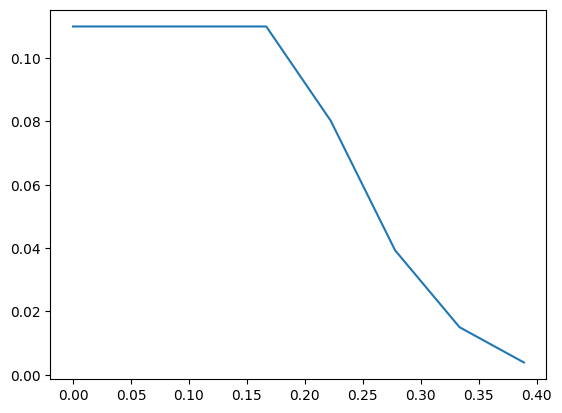

In [17]:
ind = np.argwhere(p_minus_ideal > 0)

plt.plot(np.linspace(0, 0.5, 10)[ind], p_minus_ideal[ind])

In [ ]:
p0_vals = np.concatenate([
    # np.logspace(-20, -3, 1000),
    np.linspace(0, 0.55, 30, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 30, dtype=np.float64)


dv_max = 5
r = 0.5
threshold = 1e-15
n = 50
# cr = 0.9
# f = 0.8
max_iters = 100

max_rho = 0
max_lmbd = 0
max_metr = 0
max_cr = 0
max_f = 0

for cr in np.linspace(0.1, 1, 2):
    for f in np.linspace(0.1, 1, 2):
        lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, p_size=20)
        print(f"cr = {cr}, f = {f}")
        print("λ(x):", lmbd)  # степень -> коэффициент
        print("ρ(x):", rho)  # степень -> коэффициент

        num_iters = 100

        results = density_evolution_grid_irregular(p0_vals, p_minus_vals, lmbd, rho, num_iters, threshold)

        mask = results > -1
        points = np.array([p0_vals[np.argwhere(mask)].ravel(), p_minus_vals[results[mask].astype(int)].ravel()])
        metr = sum((points[1, 1:] + points[1, :-1] + (1e-20 / 30)) * (points[0, 1:] - points[0, :-1]))
        print(f"{metr:e}")
        if metr > max_metr:
            max_rho = rho
            max_lmbd = lmbd
            max_metr = metr
            max_cr = cr
            max_f = f

In [ ]:
max_lmbd, max_rho, max_f, max_cr, max_metr

({3: 0.9413287470028247, 4: 0.05867125299717537},
 {6: 0.8973253072549428, 7: 0.10267469274505725},
 np.float64(0.8),
 np.float64(0.7000000000000001),
 np.float64(0.02007074910820452))

In [ ]:
dv_max = 10
r = 0.5
threshold = 1e-15
n = 100
cr = 0.7
f = 0.8
max_iters = 100

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, type_of_metric=0, p_size=100, p_minus_find_iters=10)
print(f"cr = {cr}, f = {f}")
print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [##################################################]100%
Task done!
cr = 0.7, f = 0.8
λ(x): {3: 0.9980476324490422, 4: 0.0019455535436126807, 6: 2.4492875158254913e-06, 8: 4.3647198293075184e-06}
ρ(x): {6: 0.9965676131431183, 7: 0.0034323868568817417}


Progress: [###########################################       ] 87%

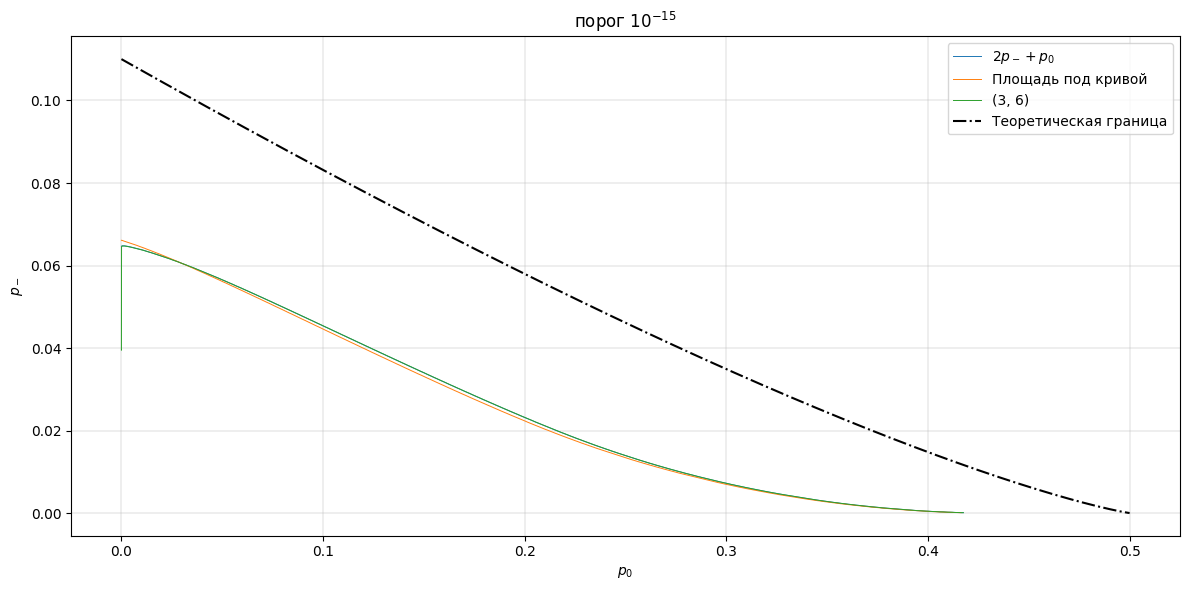

In [ ]:
plt.figure(figsize=(12, 6))
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(1e-3, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)

threshold = 1e-15

not_r = 2

num_iters = 100
p_minus_find_iters = 10

# 2p_- + p_0
lmbd = {3: 0.9980476324490422, 4: 0.0019455535436126807, 6: 2.4492875158254913e-06, 8: 4.3647198293075184e-06}
rho = {6: 0.9965676131431183, 7: 0.0034323868568817417}
results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

mask = results > -1
points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
plt.plot(points[0, :], points[1, :], label=f'$2p_- + p_0$', linewidth=0.7)

# Площадь под кривой
lmbd = {3: 0.9161037061405171, 4: 0.07342964024367607, 7: 0.0013851114702873432, 10: 0.009081542145519504}
rho = {6: 0.8214581271793703, 7: 0.17854187282062972}
results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

mask = results > -1
points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
plt.plot(points[0, :], points[1, :], label=f'Площадь под кривой', linewidth=0.7)

for l in range(3, 4):
    results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, {l:1}, {(not_r*l):1}, num_iters, threshold)

    mask = results > -1
    points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
    plt.plot(points[0, :], points[1, :], label=f'({l}, {l*not_r})', linewidth=0.7)

plt.plot(*decoding_limit(), label="Теоретическая граница", color='black', linestyle='-.')
plt.title(f'порог $10^{{{int(np.log10(threshold))}}}$')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend()
plt.tight_layout()

In [9]:
dv_max = 30
r = 0.5
threshold = 1e-15
n = 50
cr = 0.7
f = 0.8
max_iters = 200
decoding_iters = 20

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, type_of_metric=1, p_size=100, decoding_iters=decoding_iters)
print(f"cr = {cr}, f = {f}")
print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [##################################################]100%
Task done!
cr = 0.7, f = 0.8
λ(x): {3: 0.07669072119536763, 4: 0.7775751300309613, 7: 0.00034561877273628263, 11: 0.0004231711374757776, 15: 0.0010759931610409054, 16: 0.00014702679347468935, 19: 0.00018488127986080287, 21: 0.00018823039259635541, 23: 0.01181966718562954, 26: 0.018733672750071307, 28: 0.06155475679069758, 29: 0.021153986925790593, 30: 0.03010714358429717}
ρ(x): {8: 0.11118319653707154, 9: 0.8888168034629285}


In [ ]:
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(0, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)


dv_max = 10
r = 0.5
threshold = 1e-15
n = 100
cr = 0.7
f = 0.8
max_iters = 100

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, type_of_metric=2, p_size=200)
print(f"cr = {cr}, f = {f}")
print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [##################################################]100%
Task done!
cr = 0.7, f = 0.8
λ(x): {3: 0.6272596571800673, 4: 0.36522750532869647, 5: 0.0006549605293132707, 6: 0.0005785689031968922, 7: 0.001108944314544839, 9: 0.005170363744181252}
ρ(x): {6: 0.3284288436338225, 7: 0.6715711563661775}


In [25]:
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(0, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)


dv_max = 10
r = 0.5
threshold = 1e-15
n = 80
cr = 0.4
f = 0.45
max_iters = 100
decoding_iters = 200

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, type_of_metric=1, p_size=100, decoding_iters=decoding_iters)
print(f"cr = {cr}, f = {f}")
print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [##################################################]100%
Task done!
cr = 0.4, f = 0.45
λ(x): {3: 0.8686130604414505, 4: 9.510159669793009e-07, 7: 3.2867583236916525e-07, 9: 4.029001388317716e-07, 10: 0.13138525696661138}
ρ(x): {6: 0.3562073816816845, 7: 0.6437926183183156}


In [ ]:
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(0, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)


dv_max = 10
r = 0.5
threshold = 1e-15
n = 100
cr = 0.7
f = 0.8
max_iters = 100

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, type_of_metric=4, p_size=200)
print(f"cr = {cr}, f = {f}")
print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [##################################################]100%
Task done!
cr = 0.7, f = 0.8
λ(x): {3: 0.813583343666186, 4: 0.0011639927747033722, 6: 0.0022292255368835424, 10: 0.1830234380222271}
ρ(x): {6: 0.09334587695626445, 7: 0.9066541230437355}


In [ ]:
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(0, 0.55, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)


dv_max = 10
r = 0.5
threshold = 1e-15
n = 100
cr = 0.7
f = 0.8
max_iters = 100

lmbd, rho = differential_evolution_poly_find(dv_max, r, threshold, n, cr, f, max_iters, type_of_metric=5, p_size=200)
print(f"cr = {cr}, f = {f}")
print("λ(x):", lmbd)  # степень -> коэффициент
print("ρ(x):", rho)  # степень -> коэффициент

Progress: [##################################################]100%
Task done!
cr = 0.7, f = 0.8
λ(x): {2: 0.15532572300815486, 3: 0.5485038166114753, 10: 0.29617046038036976}
ρ(x): {6: 0.09240477466473057, 7: 0.9075952253352695}


Progress: [###########################################       ] 86%

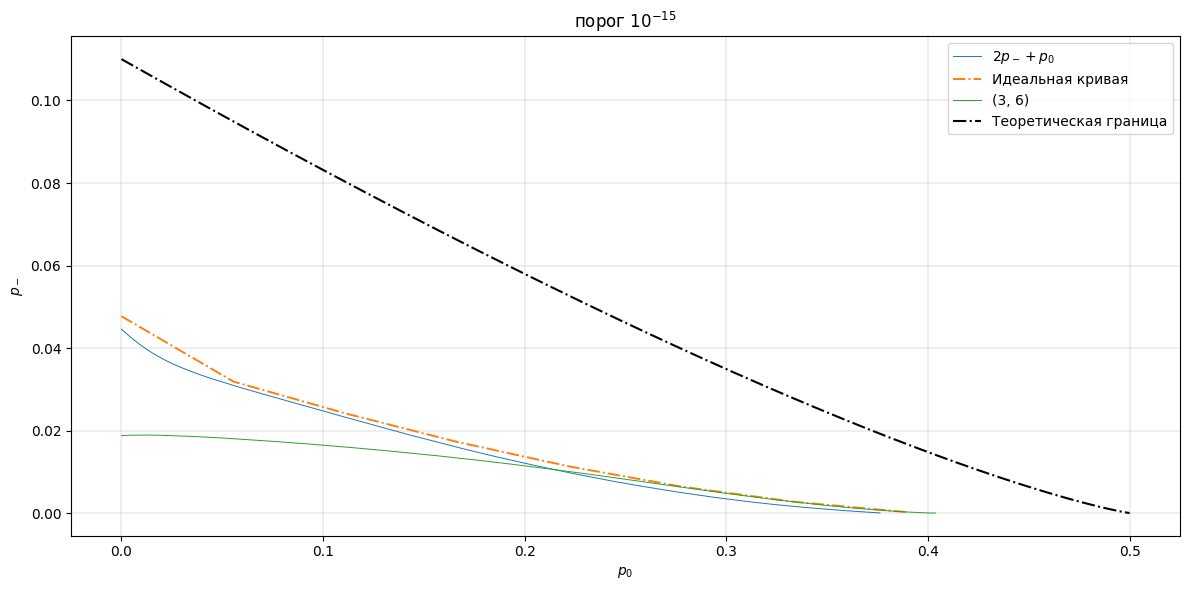

In [29]:
plt.figure(figsize=(12, 6))
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 200),
    np.linspace(1e-3, 0.55, 200, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)

threshold = 1e-15

not_r = 2

num_iters = 20
p_minus_find_iters = 10

# 2p_- + p_0
lmbd = {3: 0.07669072119536763, 4: 0.7775751300309613, 7: 0.00034561877273628263, 11: 0.0004231711374757776, 15: 0.0010759931610409054, 16: 0.00014702679347468935, 19: 0.00018488127986080287, 21: 0.00018823039259635541, 23: 0.01181966718562954, 26: 0.018733672750071307, 28: 0.06155475679069758, 29: 0.021153986925790593, 30: 0.03010714358429717}
rho = {8: 0.11118319653707154, 9: 0.8888168034629285}
results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

mask = results > -1
points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
plt.plot(points[0, :], points[1, :], label=f'$2p_- + p_0$', linewidth=0.7)

# # 6p_- + p_0
# lmbd = {3: 0.6272596571800673, 4: 0.36522750532869647, 5: 0.0006549605293132707, 6: 0.0005785689031968922, 7: 0.001108944314544839, 9: 0.005170363744181252}
# rho = {6: 0.3284288436338225, 7: 0.6715711563661775}
# results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

# mask = results > -1
# points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
# plt.plot(points[0, :], points[1, :], label=f'$6p_- + p_0$', linewidth=0.7)

# # p_-
# lmbd = {3: 0.5916738786973649, 4: 0.40832612130263524}
# rho = {6: 0.2854292877203891, 7: 0.7145707122796109}
# results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

# mask = results > -1
# points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
# plt.plot(points[0, :], points[1, :], label=f'$p_-$', linewidth=0.7)

# # Площадь под кривой
# lmbd = {3: 0.9161037061405171, 4: 0.07342964024367607, 7: 0.0013851114702873432, 10: 0.009081542145519504}
# rho = {6: 0.8214581271793703, 7: 0.17854187282062972}
# results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

# mask = results > -1
# points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
# plt.plot(points[0, :], points[1, :], label=f'Площадь под кривой', linewidth=0.7)

# # p_- + 2p_0
# lmbd = {3: 0.813583343666186, 4: 0.0011639927747033722, 6: 0.0022292255368835424, 10: 0.1830234380222271}
# rho = {6: 0.09334587695626445, 7: 0.9066541230437355}
# results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

# mask = results > -1
# points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
# plt.plot(points[0, :], points[1, :], label=f'$p_- + 2p_0$', linewidth=0.7)

# # p_- + 6p_0
# lmbd = {2: 0.15532572300815486, 3: 0.5485038166114753, 10: 0.29617046038036976}
# rho = {6: 0.09240477466473057, 7: 0.9075952253352695}
# results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

# mask = results > -1
# points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
# plt.plot(points[0, :], points[1, :], label=f'$p_- + 6p_0$', linewidth=0.7)

plt.plot(np.linspace(0, 0.5, 10)[ind], p_minus[ind], label="Идеальная кривая", linewidth=1.4, linestyle='-.')

for l in range(3, 4):
    lmbd = {l:1}
    rho = {not_r*l:1}
    results = density_evolution_grid_irregular(p0_vals, 0.09, p_minus_find_iters, lmbd, rho, num_iters, threshold)

    mask = results > -1
    points = np.array([p0_vals[np.argwhere(mask)].ravel(), results[mask].ravel()])
    plt.plot(points[0, :], points[1, :], label=f'({l}, {l*not_r})', linewidth=0.7)

plt.plot(*decoding_limit(), label="Теоретическая граница", color='black', linestyle='-.')
plt.title(f'порог $10^{{{int(np.log10(threshold))}}}$')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend()
plt.tight_layout()